In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df=pd.read_csv("/content/credit_risk_dataset.csv")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
df.shape

(32581, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [ ]:
df["loan_status"].unique()

array([1, 0])

In [ ]:
df["loan_status"].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

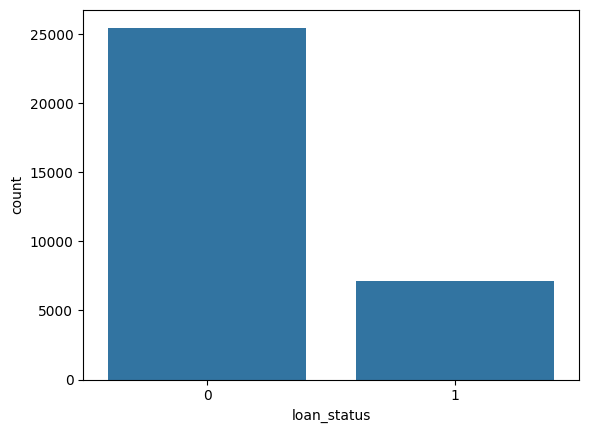

In [ ]:
sns.countplot(x="loan_status",data=df)

In [ ]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

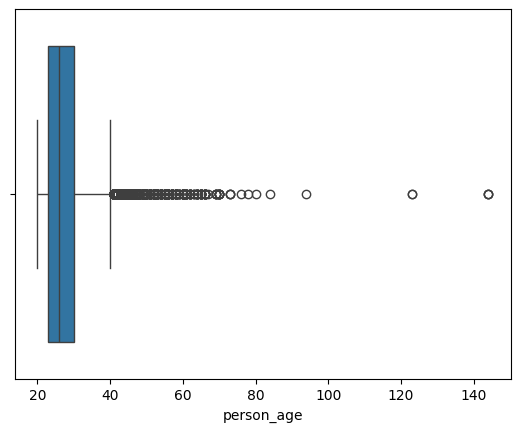

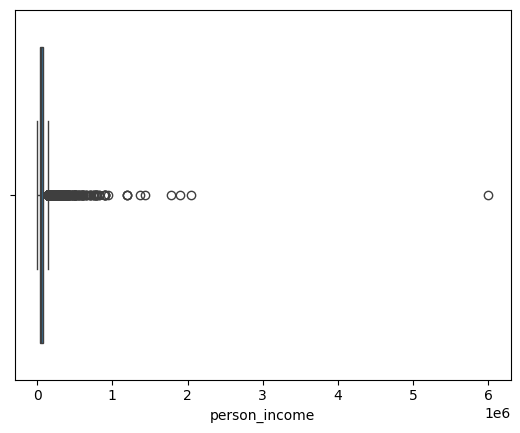

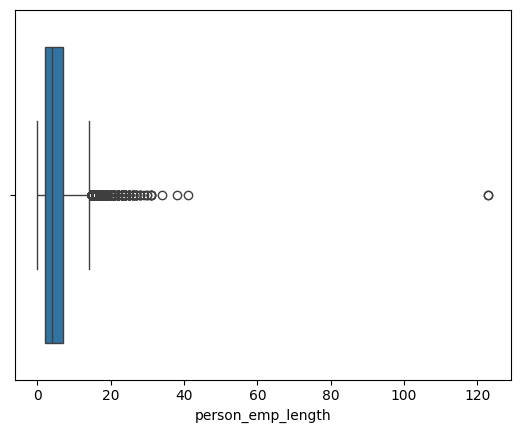

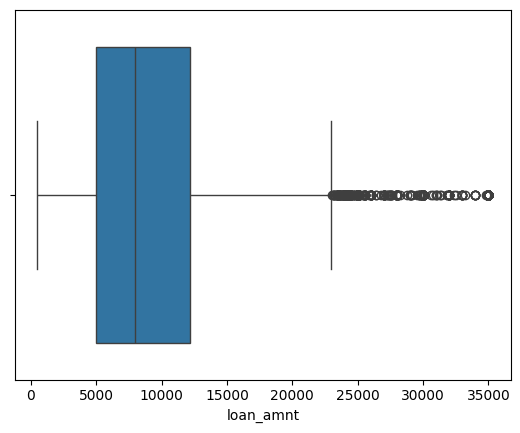

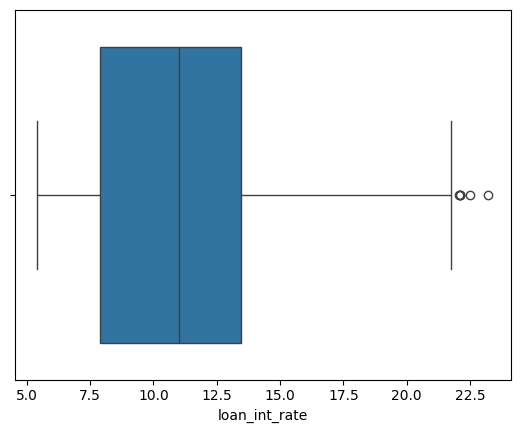

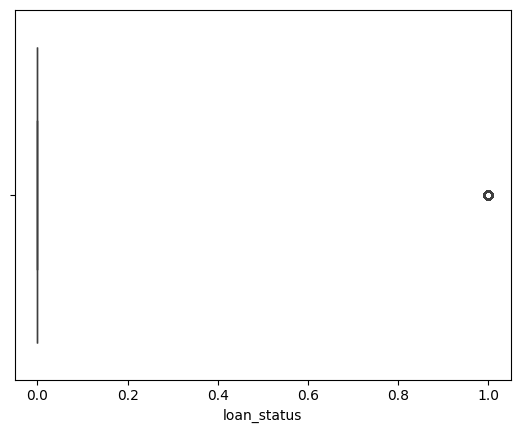

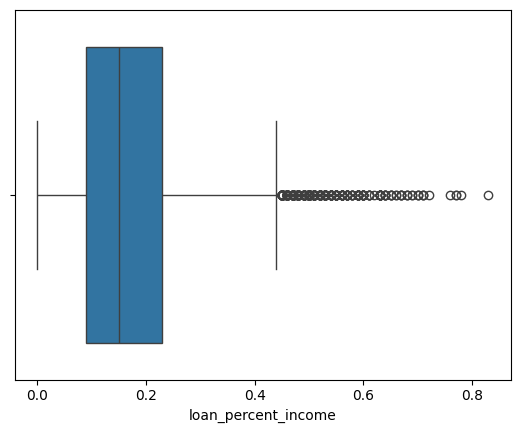

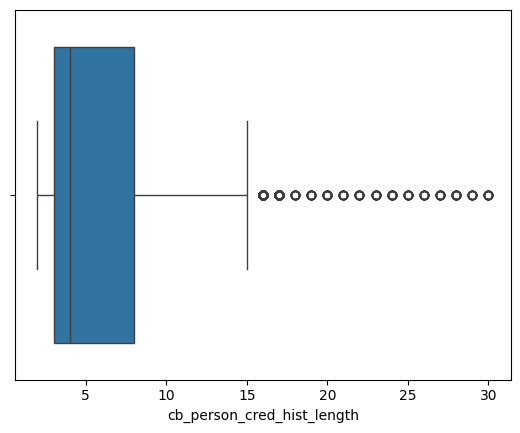

In [ ]:
numerical_cols=df.select_dtypes(include=np.number).columns

for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()


In [ ]:
(df["person_age"]>100).sum()

np.int64(5)

In [ ]:
(df["person_emp_length"]>60).sum()

np.int64(2)

In [ ]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


<Axes: >

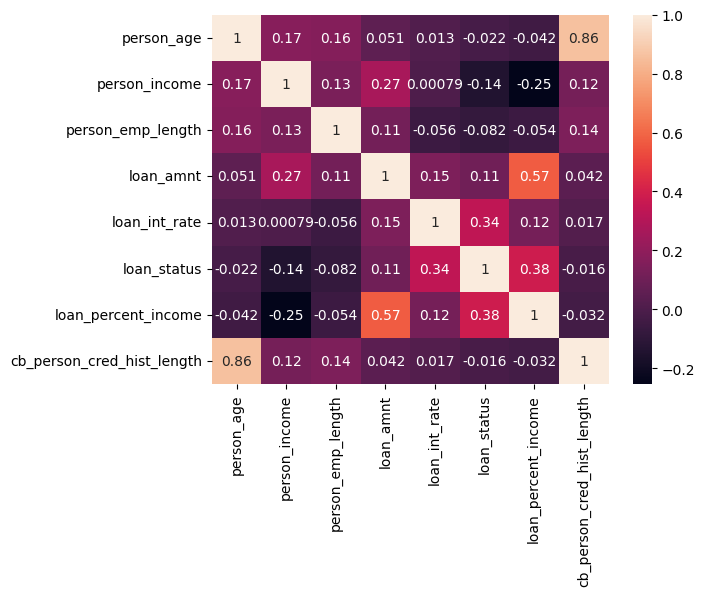

In [ ]:
from pandas.core.arrays import numeric
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [ ]:
df_copy = df.copy()

In [ ]:
#removing duplicate rows

In [ ]:
df_copy.drop_duplicates(inplace=True)
print(f"rows after removing duplicates: {df_copy.shape[0]}")

rows after removing duplicates: 32416


In [ ]:
df_copy = df_copy[df_copy["person_age"] >= 18]
df_copy = df_copy[df_copy['person_age'] < 100]

In [ ]:
df_copy = df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length'] <= 60]


In [ ]:
df_copy=df_copy[df_copy["loan_amnt"]>0]

In [ ]:
print("Loan intreset rate range from (min: 5.42 and max: 23.22)")

Loan intreset rate range from (min: 5.42 and max: 23.22)


In [ ]:
#features,target&train_test_spilt

In [ ]:
x=df_copy.drop("loan_status",axis=1)
y=df_copy["loan_status"]

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']



In [ ]:
neg,pos=np.bincount(y_train)
scale_weights=neg/pos
scale_weights

np.float64(3.6312213039485766)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

#logisitic regression

In [ ]:
preprocessor_lr = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ]
)

#XGBoost

In [ ]:
prprocessor_xg=ColumnTransformer(
    transformers=[
        ("num",Pipeline([
            ("imputer",SimpleImputer(strategy="median")),

        ]),numeric_cols),
        ("cat",Pipeline([
            ("imputer",SimpleImputer(strategy="constant",fill_value="missing")),
            ("onehot",OneHotEncoder(handle_unknown="ignore"))
        ]),categorical_cols)
    ]
)

#Stratified Cross-Validation

In [ ]:

from sklearn.model_selection import StratifiedKFold,cross_validate

cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [ ]:
scoring={"roc_auc":"roc_auc","accuracy":"accuracy","precision":"precision","recall":"recall","f1":"f1"}

In [ ]:
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline=Pipeline([
    ("preprocessor",preprocessor_lr),
    ("classifier",LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42))
])

In [ ]:
import pip
!pip install xgboost

In [ ]:
from xgboost import XGBClassifier
xg_cv_pipeline = Pipeline([
    ("preprocessor", prprocessor_xg),
    ("classifier", XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1, scale_pos_weight=scale_weights, random_state=42))
])

In [ ]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                     ("XGBoost", xg_cv_pipeline)]:

    cv_results = cross_validate(pipe, x_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    print(cv_name)
    print(f"ROC-AUC : {cv_results['test_roc_auc'].mean()}")
    print(f"Accuracy : {cv_results['test_accuracy'].mean()}")
    print(f"Precision : {cv_results['test_precision'].mean()}")
    print(f"Recall : {cv_results['test_recall'].mean()}")
    print(f"F1 : {cv_results['test_f1'].mean()}")
    print()

Logistic Regression
ROC-AUC : 0.8705112830525306
Accuracy : 0.8115949542892269
Precision : 0.5448226008889892
Recall : 0.7781450872359963
F1 : 0.6408013995933108

XGBoost
ROC-AUC : 0.9470945968526715
Accuracy : 0.917952083139717
Precision : 0.8190795992296656
Recall : 0.7963269054178144
F1 : 0.8073360762846882



Baseline Model — Logistic Regression

In [ ]:
from sklearn.pipeline import Pipeline
baseline_model=Pipeline([
    ("preprocessor",preprocessor_lr),
    ("classifier",LogisticRegression(class_weight="balanced"))
])

baseline_model.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

Evaluation function for xgboost and logistic regression

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, precision_recall_curve
import matplotlib.pyplot as plt
import seaborn as sns

def evalute_model(model_name, model, x_test, y_test, threshold=None):
  y_pred_prob = model.predict_proba(x_test)[:, 1]

  if threshold:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(x_test)

  # metrics (renamed variables to avoid shadowing function names)
  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred)
  rec = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)

  # confusion matrix
  cm = confusion_matrix(y_test, y_pred)
  class_report = classification_report(y_test, y_pred)

  print(f"{model_name} Metrics:")
  if threshold is not None:
    print(f"used threshold :{threshold:.2f}")
  print(f"Accuracy: {acc:.2f}")
  print(f"Precision: {prec:.2f}")
  print(f"Recall: {rec:.2f}")
  print(f"F1 score: {f1:.2f}")
  print()
  print(f"{model_name} classification_report:")
  print(class_report)

  # plotting confusion matrix
  sns.heatmap(cm, annot=True, fmt="d")
  plt.title(f"{model_name} confusion matrix")
  plt.ylabel("Actual values")
  plt.xlabel("Predicted values")
  plt.show()

  # plotting ROC-AUC CURVE
  precisions, recall, thresholds = precision_recall_curve(y_test, y_pred_prob)

  plt.plot(recall, precisions)
  plt.xlabel("recall")
  plt.ylabel("precision")
  plt.title(f"{model_name} precision-recall curve")
  plt.show()

#Evaluate the Logistic Model.

LogisticRegression Metrics:
Accuracy: 0.82
Precision: 0.56
Recall: 0.79
F1 score: 0.65

LogisticRegression classification_report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



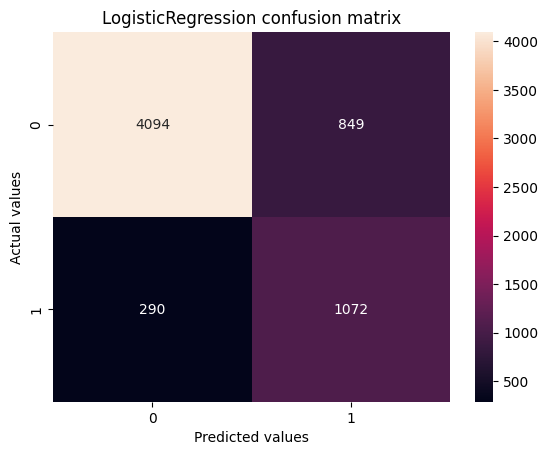

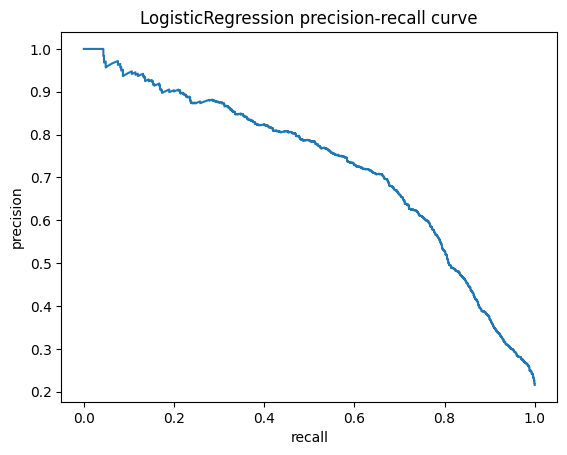

In [ ]:
evalute_model("LogisticRegression",baseline_model,x_test,y_test)

#As we know XGBOOST IS MORE POWERFUL IN OVERALL PERFORMANCE IN OUR PROJECT SO WE WILL PERFORM Hyperparmeter tuning of our xgboost model

In [ ]:
xg_model = Pipeline([
    ('preprocessor', prprocessor_xg),
    ('classifier', XGBClassifier(learning_rate=0.1,
        scale_pos_weight=scale_weights,random_state=42))
])
xg_model.fit(x_train, y_train)



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

# scipy - libary can we used for getting list of numbers for hyperparameter tuning.

# nut numpy - np.random.randint can't be used because they provide a random single number everytime.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

In [ ]:
param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth": randint(3, 9),
    "classifier__learning_rate": uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6, 0.4),  # Corrected with __
    "classifier__colsample_bytree": uniform(0.6, 0.4),  # Corrected with __
    "classifier__gamma": uniform(0, 5)  # Corrected with __
}


The double underscore (__) is used to access a parameter inside a pipeline.

Learning rate is a hyperparameter that controls how much a machine learning model changes its parameters (weights) during each training step.

In simple words:

It decides how big a step the model takes when learning from its mistakes.

# lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gamma -> less splits ->  simpler tree -> low overfitting


In [ ]:
random_search=RandomizedSearchCV(
    xg_model,
    param_distributions=param_grid,
    n_iter=150,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    verbose=1
)


In [ ]:
# Redefine param_grid with double underscores (__) to correctly target the XGBoost classifier inside the Pipeline
param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth": randint(3, 9),
    "classifier__learning_rate": uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6, 0.4),  # Corrected with __
    "classifier__colsample_bytree": uniform(0.6, 0.4),  # Corrected with __
    "classifier__gamma": uniform(0, 5)  # Corrected with __
}

random_search = RandomizedSearchCV(
    xg_model,
    param_distributions=param_grid,
    n_iter=150,
    cv=cv,
    scoring=scoring,
    refit="f1",  # Tells scikit-learn to optimize for F1-score to choose the best estimator
    n_jobs=-1,
    verbose=1
)

random_search.fit(x_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a9451083950>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7a94510b8cd0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7a94510cc050>},
                   refit='f1',
                   scoring={'accuracy': 'accuracy', 'f1': 'f1',
                            'precision': 'precision', 'recall': 'recall',
                            'roc_auc': 'roc_auc'},
                   verbose=1)

In [ ]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.8957773312296352),
 'classifier__gamma': np.float64(0.001920219895600872),
 'classifier__learning_rate': np.float64(0.16605107560659327),
 'classifier__max_depth': 8,
 'classifier__n_estimators': 299,
 'classifier__subsample': np.float64(0.982814876836463)}

comparing both the models

LogisticRegression Metrics:
Accuracy: 0.82
Precision: 0.56
Recall: 0.79
F1 score: 0.65

LogisticRegression classification_report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



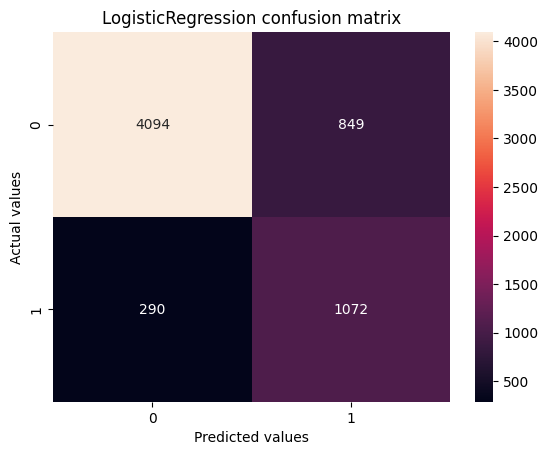

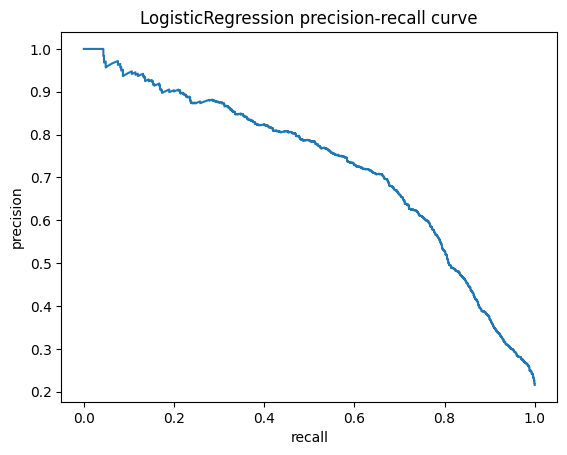

In [ ]:
evalute_model("LogisticRegression",baseline_model,x_test,y_test)

XGBoost Metrics:
Accuracy: 0.92
Precision: 0.82
Recall: 0.79
F1 score: 0.81

XGBoost classification_report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



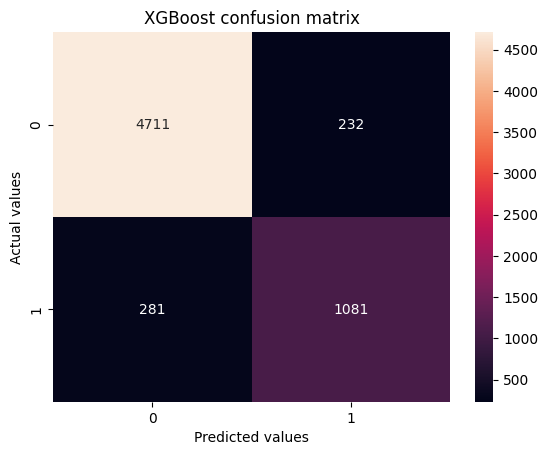

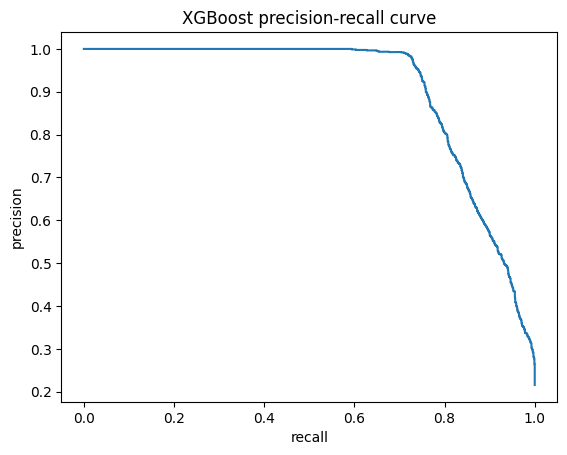

In [ ]:
evalute_model("XGBoost",xg_model,x_test,y_test)

Optimizing the Classification Threshold

In [ ]:
#Getting the prob. of class 1 from XGBoost

prob = xg_model.predict_proba(x_test)[:,1]

#For each threshold calculate Precision and Recall
precision,recall,threshold = precision_recall_curve(y_test,prob)

#calcuating f1 score for each student
f1=2*(precision*recall)/(precision + recall)

#Get the threshold that produces the highest f1-score
best=np.argmax(f1[:-1])
best_threshold = threshold[best]

XGBoost Metrics:
used threshold :0.76
Accuracy: 0.94
Precision: 0.98
Recall: 0.73
F1 score: 0.83

XGBoost classification_report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      4943
           1       0.98      0.73      0.83      1362

    accuracy                           0.94      6305
   macro avg       0.96      0.86      0.90      6305
weighted avg       0.94      0.94      0.93      6305



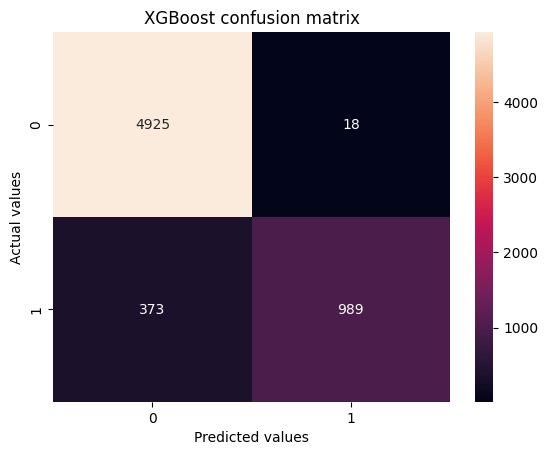

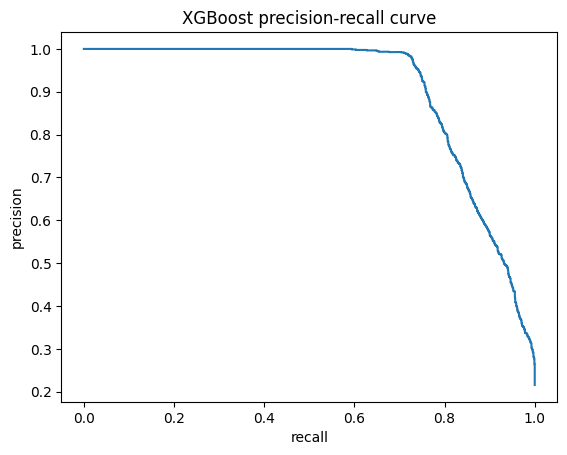

In [ ]:
evalute_model("XGBoost", xg_model, x_test, y_test, best_threshold)

Probability Calibration

Sometimes a model's probability doesn't mean what it says.

For example, 30% risk should truly mean a 30% chance.

We check this with a calibration plot.

In [ ]:
from sklearn.calibration import CalibratedClassifierCV,calibration_curve

best_model=random_search.best_estimator_
calibrated_model=CalibratedClassifierCV(best_model,method="sigmoid",cv=5)

calibrated_model.fit(x_train,y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.16605107560659327),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=8,
                                                                max_leaves=None,
                                                                min_child_weight=None,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=299,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [ ]:
uncalibrated = xg_model.predict_proba(x_test)[:,-1]
calibrated = calibrated_model.predict_proba(x_test)[:,-1]

In [ ]:
actual_uncal , predicted_uncal = calibration_curve(y_test,uncalibrated,n_bins=10)


In [ ]:
acutal_cal,prdicated_cal = calibration_curve(y_test,calibrated ,n_bins=10)

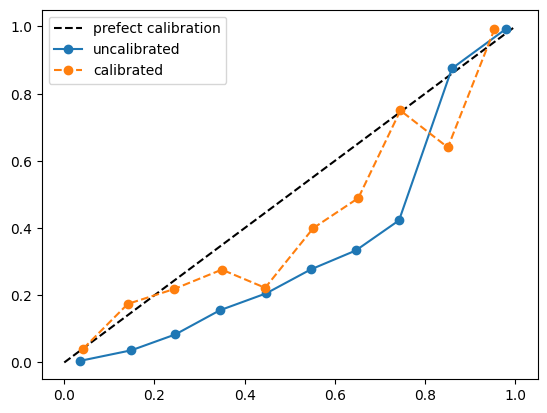

In [ ]:
plt.plot([0,1],[0,1],"k--",label="prefect calibration")
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label="uncalibrated"
)

plt.plot(
    prdicated_cal ,
    acutal_cal,
    "o--",
    label="calibrated"
)

plt.legend()

NOTE - Methods by which we can fix the poorly calibrated model.

1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.


2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)

#SHAP

In [ ]:
!pip install shap
import shap

In [ ]:
#2. Get the Trained XGBoost classifier model out of the pipeline.
xgb_classifier = xg_model.named_steps["classifier"]

In [ ]:
#3. Transform X_test using the same preprocessing used for training.
x_test_transformed = xg_model.named_steps["preprocessor"].transform(x_test)

In [ ]:
# Get feature names after one-hot enocding , so plots are readable
feature_names = xg_model.named_steps["preprocessor"].get_feature_names_out()

In [ ]:
#5. Convert to a dataframe for cleaner SHAP plots
x_test_df = pd.DataFrame(x_test_transformed,columns=feature_names)

In [ ]:
#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [ ]:

#7. Calculate SHAP values for every row in the test set
shap_values=explainer.shap_values(x_test_df)
shap_values

array([[-1.7525564e-01, -1.0555401e-01,  1.2984274e-01, ...,
        -7.3516299e-03, -3.8879909e-02,  0.0000000e+00],
       [ 4.7165085e-02, -8.7262326e-01, -9.4737314e-02, ...,
        -9.2151780e-03, -7.5508673e-03,  0.0000000e+00],
       [ 7.8027323e-02,  3.5025654e+00,  1.2711690e-01, ...,
        -7.3584518e-03,  7.7456667e-04,  0.0000000e+00],
       ...,
       [-8.6244913e-03,  5.8208084e-01,  7.2391242e-02, ...,
        -9.2837382e-03, -1.1459960e-02,  0.0000000e+00],
       [ 2.0838849e-02, -1.0313793e+00,  4.3692421e-02, ...,
        -9.2305308e-03, -1.1398584e-02,  0.0000000e+00],
       [-1.3665082e-01, -5.0866711e-01,  2.6854105e-02, ...,
        -8.8342456e-03, -1.0388625e-02,  0.0000000e+00]],
      shape=(6305, 26), dtype=float32)

Global explanation

This shows which features matter most overall.

It also shows if a feature increases or decreases risk.

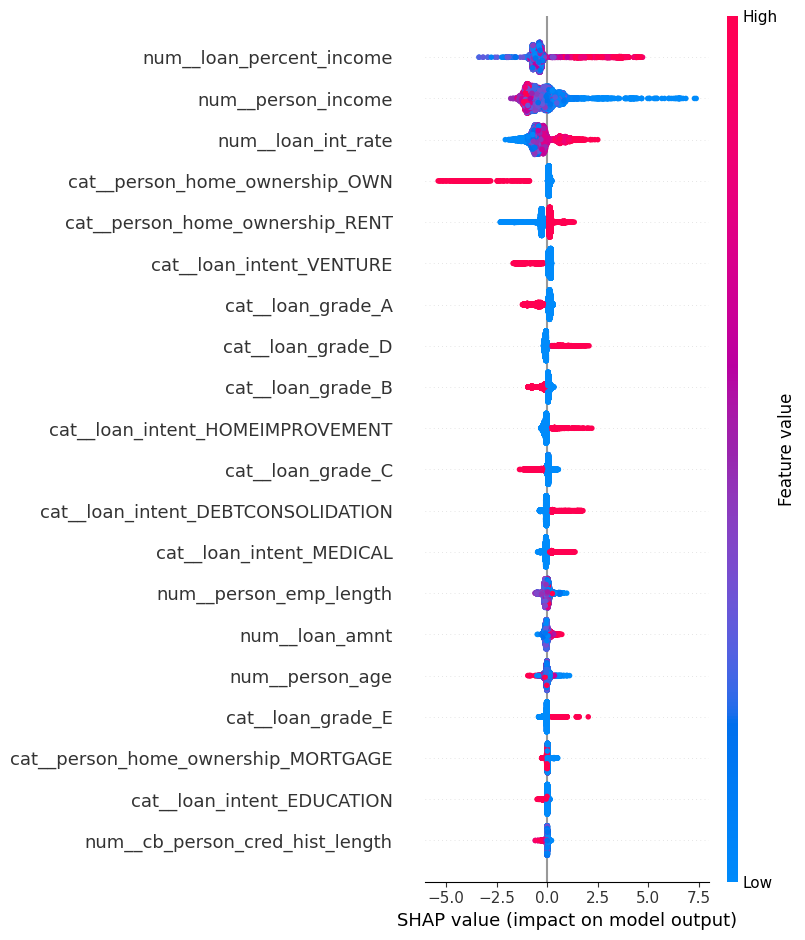

In [ ]:
shap.summary_plot(shap_values,x_test_df)

Local explanation

This shows why one specific applicant got their score.

It breaks the score down feature by feature.

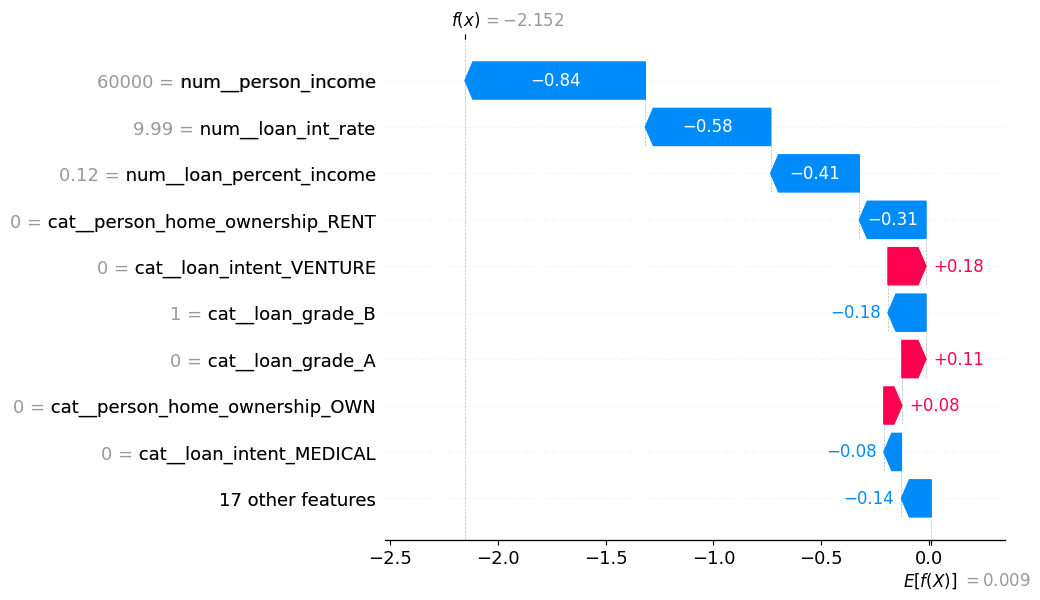

In [ ]:
row_index=5

shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,# predicted percentage by shap.
        data = x_test_df.iloc[row_index],
        feature_names = feature_names

    )
)

In [ ]:
#saving the model

import joblib
joblib.dump(calibrated_model,"credit_risk.pkl")

['credit_risk.pkl']

In [ ]:
joblib.dump(best_threshold,"best_threshold.pkl")

['best_threshold.pkl']

In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

calibrated_proba = calibrated_model.predict_proba(x_test)[:, 1]

precision, recall, threshold = precision_recall_curve(y_test, calibrated_proba)

f1 = 2 * (precision * recall) / (precision + recall)
best_idx = np.argmax(f1[:-1])
best_threshold = threshold[best_idx]